In [2]:
from clustering.Cluster import *
from data_access.DataProvider import *
import numpy as np

data_provider = DataProvider()
rows = data_provider.get_articles('PL')

corpus = [row[0] for row in rows[0:100]] + [row[1] for row in rows[0:100]]
results = [row[2] for row in rows[0:100]]


In [3]:
from models.Model import TfIdfModel
tf = TfIdfModel()

matrix = tf.Transform(corpus)


c:\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [13]:
kmeans = KMeansCluster()
# Perform KMeans clustering
cluster_assignments = kmeans.create_clusters(matrix, 8)

# Print the cluster assignments for each document
for res, cluster in zip(corpus, cluster_assignments):
    print(f"Document: {res[0:100]}\nCluster: {cluster}\n")


Document: Ukraińska kontrofensywa przebiega wolniej, niż zak
Cluster: 3

Document: Ukraińska kontrofensywa przebiega wolniej, niż zak
Cluster: 3

Document: Ukraińska kontrofensywa przebiega wolniej, niż zak
Cluster: 3

Document: Ukraińska kontrofensywa przebiega wolniej, niż zak
Cluster: 3

Document: Ukraińska kontrofensywa przebiega wolniej, niż zak
Cluster: 3

Document: Ukraińska kontrofensywa przebiega wolniej, niż zak
Cluster: 3

Document: Ukraińska kontrofensywa przebiega wolniej, niż zak
Cluster: 3

Document: Ukraińska kontrofensywa przebiega wolniej, niż zak
Cluster: 3

Document: Instytut Meteorologii i Gospodarki Wodnej ostrzegł
Cluster: 6

Document: Instytut Meteorologii i Gospodarki Wodnej ostrzegł
Cluster: 6

Document: Instytut Meteorologii i Gospodarki Wodnej ostrzegł
Cluster: 6

Document: Instytut Meteorologii i Gospodarki Wodnej ostrzegł
Cluster: 6

Document: Instytut Meteorologii i Gospodarki Wodnej ostrzegł
Cluster: 6

Document: Instytut Meteorologii i Gospodarki Wodnej

c:\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


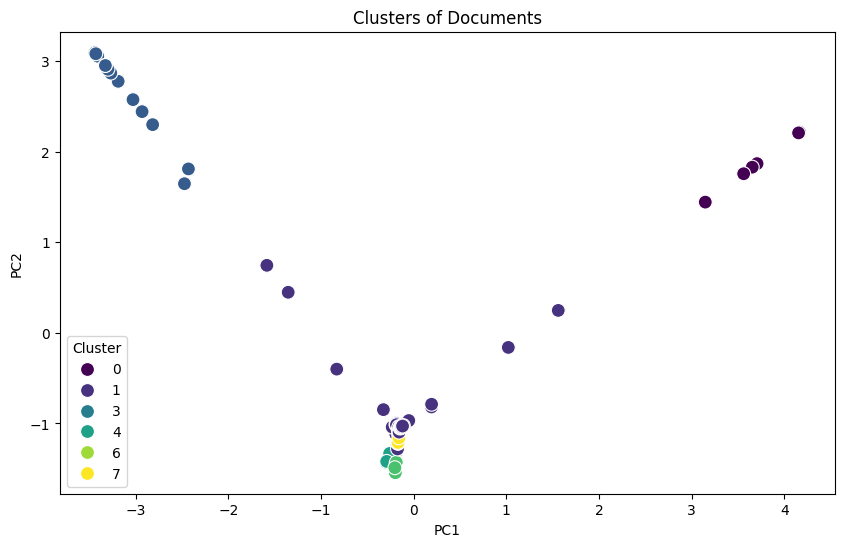

In [14]:
from sklearn.decomposition import PCA
import seaborn as sns

pca = PCA(n_components=2, random_state=42)
tfidf_matrix_2d = pca.fit_transform(matrix)

# Create a DataFrame for plotting
import pandas as pd
df = pd.DataFrame({
    'Document': corpus,
    'Cluster': cluster_assignments,
    'PC1': tfidf_matrix_2d[:, 0],
    'PC2': tfidf_matrix_2d[:, 1]
})

# Plot the clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='Cluster', data=df, palette='viridis', s=100)
plt.title('Clusters of Documents')
plt.show()

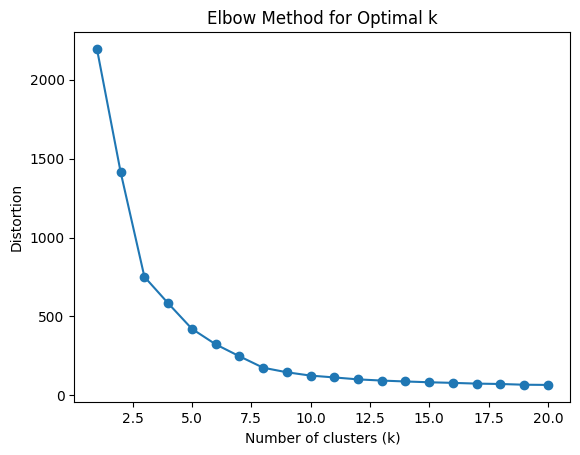

In [15]:
import matplotlib.pyplot as plt
import numpy as np

def find_optimal_clusters(tfidf_matrix, max_clusters=20):
    distortions = []
    for i in range(1, max_clusters + 1):
        kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
        kmeans.fit(tfidf_matrix)
        distortions.append(kmeans.inertia_)

    plt.plot(range(1, max_clusters + 1), distortions, marker='o')
    plt.title('Elbow Method for Optimal k')
    plt.xlabel('Number of clusters (k)')
    plt.ylabel('Distortion')
    plt.show()

find_optimal_clusters(matrix)

In [36]:
from textpreprocessing.TextPreprocessing import PolishTextPreprocessor

polish_pr = PolishTextPreprocessor()
for i in range(len(result)):
    result[i] = polish_pr.preprocess_text(result[i])
    result[i] = ' '.join(result[i])

In [9]:
from models.Model import PolishBertModel

tf = PolishBertModel()


In [ ]:
mat = []
for i in range(100):
    mat.append(tf.Transform(result[0 + i], result[100 +i]))
np.set_printoptions(suppress=True)

print(mat)

In [6]:
from models.Model import TfIdfModel
tf2 = TfIdfModel()


In [ ]:

mat2 = tf2.Transform(result)
tfidf_res = []

for i in range(100):
    tfidf_res.append(mat2[0 + i][100 + i])

print(tfidf_res)
tfidf_res[41]


In [41]:
nm_res = [row[2] for row in rows[0:100]]

a = [x - y for x, y in zip(nm_res,tfidf_res)]
a


[0.016644555694502017,
 0.03258459247194467,
 0.028734701987534708,
 0.017223900922212487,
 -0.004486822263032222,
 0.024774648603989036,
 0.00599517178647898,
 0.0066960667487669075,
 0.004791935561886623,
 0.0052139692330316345,
 0.0013974688578938244,
 0.02036552819630011,
 0.07724668868765283,
 0.008694388887245278,
 0.07086143881398249,
 0.0022771520046175886,
 0.02751909677541209,
 0.11938730419212562,
 0.02551316017294336,
 0.008054342508738682,
 0.029942541035263393,
 0.02805746001140172,
 -0.0010007052809236335,
 0.001238502573068484,
 0.006060202807165551,
 0.026545314833111067,
 0.0029910026094507377,
 0.02354335598560664,
 0.0232910593750999,
 0.000422639429658634,
 0.0010077060120274942,
 0.076072462876416,
 0.10156746690831697,
 0.11790050280764308,
 0.13824717747094406,
 0.061887712169644504,
 0.11093394695873549,
 -0.0009381488220862044,
 0.03161472022725664,
 0.03120303816610115,
 0.14330995622047893,
 0.0014766865339989055,
 0.2648934145700536,
 0.0067316496514227536,